# Marche aléatoire — où part le temps ?

Portage de la marche aléatoire de **RevoMol-correlation** (`scripts/walk.py`, `strategy="random"`) dans
`evomol.search.random_walk`, puis mesure des appels qui coûtent.

À chaque pas : on liste les voisins distincts de la molécule courante (une mutation), on les mélange,
et on avance vers le **premier voisin valide** (Hückel → ChEMBL/ZINC → Hetero). C'est la même loi
(uniforme sur les voisins valides) que l'original, qui validait *tout* le voisinage avant de tirer.

| Section | Question |
|---|---|
| 1 | Une marche : combien de temps par pas, dans quelle phase ? |
| 2 | Validation paresseuse (défaut) vs complète (comportement de l'original) |
| 3 | Coût et taux de rejet de chaque filtre |
| 4 | Coût par type de mutation (lister les actions + produire les voisins) |
| 5 | cProfile : quelles fonctions prennent le temps |
| 6 | Ce que coûtait l'original (`setup_filters` rappelé pour chaque voisin) |

## Paramètres et initialisation

In [1]:
import json, os, subprocess, sys, time, pstats
from collections import defaultdict
from pathlib import Path

# racine du projet = premier dossier parent qui contient evomol/
ROOT = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir()))
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, "scripts", "Lea"))  # huckel_filters, random_walk_core
os.chdir(ROOT)  # les filtres ChEMBL/ZINC lisent external_data/ en relatif

import matplotlib.pyplot as plt
import pandas as pd
from rdkit import RDLogger

from evomol import default_parameters as dp
from evomol.action import molecular_graph as mg
from evomol.evaluation import EvaluationError, Huckel, HuckelHOMO
from evomol.representation import MolecularGraph, Molecule
import huckel_filters as hf
from random_walk_core import random_walk

RDLogger.DisableLog("rdApp.*")

START         = "C=CC=Cc2cccc(C=Cc1ccccc1)c2"
N_STEPS       = 300   # marche principale (sections 1 et 5)
N_STEPS_EAGER = 50    # section 2 (validation complète : ~6x plus lente)
MAX_ATOMS     = 30
UNIQUE_KEKULE = False  # True : un seul SMILES par molécule aromatique (plus lent)

# ── Options de la marche ── (entre parenthèses : valeur qui reproduit l'original)
ONLY_VALID            = True   # n'avancer que vers des voisins valides                     (True)
COUNT_VALID_NEIGHBORS = False  # valider tout le voisinage à chaque pas                     (True)
SEED                  = 0      # None : marche différente à chaque exécution
EXCLUDE_CURRENT       = True   # la molécule courante n'est jamais tirée comme voisin       (False)

# Mutations autorisées pendant la marche. None : toutes celles de l'espace d'action configuré
# (ci-dessous). Sinon une liste parmi mg.AddAtomMG, ChangeBondMG, CutAtomMG, InsertCarbonMG,
# MoveGroupMG, RemoveAtomMG, SubstituteAtomMG.
ACTION_TYPES = [mg.AddAtomMG, mg.RemoveAtomMG, mg.ChangeBondMG]
# ACTION_TYPES = [mg.AddAtomMG, mg.SubstituteAtomMG]

# ── Espace d'action ──
INSERT_CARBON       = True   # InsertCarbonMG disponible (son C inséré est toujours rejeté par Hückel)
AVOID_SP3_ON_SP3    = False  # AddAtomMG ne greffe pas de C sp3 sur un C sp3
ADD_ATOM_MULTIPLE_BONDS = True  # AddAtomMG peut greffer par double / triple liaison (=CH2, =O, #N…)
AVOID_BOND_BREAKING = False  # ChangeBondMG ne supprime jamais de liaison
AVOID_BOND_FORMING  = False  # ChangeBondMG ne crée jamais de liaison

# ── Filtres ── ordre : Hückel → sp3 → ChEMBL/ZINC → Hetero
FILTER_HUCKEL  = True           # HuckelCompatible
MAX_SP3        = None           # None : inactif ; entier : nb max d'atomes sans liaison π
FILTER_REALISM = "chembl_zinc"  # "chembl_zinc", "chembl" ou None
FILTER_HETERO  = True           # HeteroatomChainFilter
MAX_RING_N     = 3              # nb max d'azotes en cycle (HeteroatomChainFilter)

dp.setup_default_parameters(accepted_atoms=hf.HUCKEL_ACCEPTED_ATOMS, max_heavy_atoms=MAX_ATOMS,
                            unique_kekule=UNIQUE_KEKULE)
dp.setup_default_action_space(
    insert_carbon=INSERT_CARBON, avoid_sp3_on_sp3=AVOID_SP3_ON_SP3,
    add_atom_multiple_bonds=ADD_ATOM_MULTIPLE_BONDS,
    avoid_bond_breaking=AVOID_BOND_BREAKING, avoid_bond_forming=AVOID_BOND_FORMING,
)

def build_filters():
    return hf.setup_huckel_filters(huckel=FILTER_HUCKEL, max_sp3=MAX_SP3, realism=FILTER_REALISM,
                                   hetero=FILTER_HETERO, max_ring_n=MAX_RING_N)

filters = build_filters()
print("Actions :", [a.__name__ for a in MolecularGraph.action_space])
print("Filtres :", [f.name for f in filters])

WALK_OPTIONS = dict(
    only_valid=ONLY_VALID, count_valid_neighbors=COUNT_VALID_NEIGHBORS, seed=SEED,
    exclude_current=EXCLUDE_CURRENT, action_types=ACTION_TYPES,
)
# mêmes réglages, traduits en options de scripts/Lea/profile_random_walk.py (section 5)
PROFILE_FLAGS = ["--seed", str(SEED), "--realism", FILTER_REALISM or "none", "--max-ring-n", str(MAX_RING_N)]
PROFILE_FLAGS += [flag for flag, on in [
    ("--no-only-valid", not ONLY_VALID), ("--count-valid-neighbors", COUNT_VALID_NEIGHBORS),
    ("--no-exclude-current", not EXCLUDE_CURRENT), ("--no-insert-carbon", not INSERT_CARBON),
    ("--unique-kekule", UNIQUE_KEKULE), ("--no-add-atom-multiple-bonds", not ADD_ATOM_MULTIPLE_BONDS),
    ("--avoid-sp3-on-sp3", AVOID_SP3_ON_SP3), ("--avoid-bond-breaking", AVOID_BOND_BREAKING),
    ("--avoid-bond-forming", AVOID_BOND_FORMING), ("--no-huckel", not FILTER_HUCKEL),
    ("--no-hetero", not FILTER_HETERO),
] if on]
if MAX_SP3 is not None:
    PROFILE_FLAGS += ["--max-sp3", str(MAX_SP3)]
if ACTION_TYPES is not None:
    PROFILE_FLAGS += ["--actions", ",".join(a.__name__ for a in ACTION_TYPES)]
print("Options :", {**WALK_OPTIONS, "action_types": [a.__name__ for a in ACTION_TYPES] if ACTION_TYPES else None})

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True, "font.size": 10,
})

def hbar(labels, values, title, xlabel, fmt="{:.2f}"):
    order = sorted(range(len(values)), key=lambda i: values[i])
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1.2))
    ax.barh([labels[i] for i in order], [values[i] for i in order], color=BLUE, height=0.6)
    for y, i in enumerate(order):
        ax.text(values[i], y, " " + fmt.format(values[i]), va="center", fontsize=9)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

Actions : ['AddAtomMG', 'ChangeBondMG', 'CutAtomMG', 'InsertCarbonMG', 'MoveGroupMG', 'RemoveAtomMG', 'SubstituteAtomMG']
Filtres : ['huckel_compatible', 'UnknownGCF_chembl_zinc', 'FilterUnknownGCF', 'UnknownECFP_chembl_zinc', 'FilterUnknownECFP', 'heteroatom_chain_filter']
Options : {'only_valid': True, 'count_valid_neighbors': False, 'seed': 0, 'exclude_current': True, 'action_types': ['AddAtomMG', 'RemoveAtomMG', 'ChangeBondMG']}


## 1 — Une marche aléatoire

`random_walk` renvoie une ligne par molécule visitée, avec le temps passé dans chaque phase du pas :
`t_neighbors` (lister + produire les voisins), `t_filters` (valider), `t_evaluations` (descripteurs, ici Hückel HOMO).

In [2]:
t0 = time.perf_counter()
rows = random_walk(START, N_STEPS, filters, evaluations=[Huckel(), HuckelHOMO()], **WALK_OPTIONS)
wall = time.perf_counter() - t0

walk = pd.DataFrame(rows).drop(columns=["huckel"])
walk["n_atoms"] = [Molecule(s).get_representation(MolecularGraph).nb_atoms for s in walk.smiles]
steps = walk.iloc[1:]

print(f"{N_STEPS} pas en {wall:.1f} s  ->  {1000 * wall / N_STEPS:.0f} ms/pas")
print(f"voisins/pas : {steps.neighborhood_size.mean():.0f}   |   appels aux filtres/pas : {steps.n_filter_calls.mean():.1f}"
      f"   |   restarts : {(steps.action == 'restart').sum()}")
print("\nMutations choisies :")
print(steps.action.value_counts().to_string())
walk.head(8)

300 pas en 17.0 s  ->  57 ms/pas
voisins/pas : 191   |   appels aux filtres/pas : 14.6   |   restarts : 0

Mutations choisies :
action
AddAtomMG       132
RemoveAtomMG    121
ChangeBondMG     47


,step,smiles,valid,action,neighborhood_size,n_valid_neighbors,n_filter_calls,t_neighbors,t_filters,t_evaluations,huckel_homo_lambda,n_atoms
0,0,C=CC=CC1=CC=CC(C=CC2=CC=CC=C2)=C1,True,None,NaN,None,0,0.000000,0.000000,0.000000,4.559416e-01,18
1,1,C=CC=CC1=CC=CC(C=CC2=CC=C(C)C=C2)=C1,True,AddAtomMG,225.0,None,1,0.049520,0.004253,0.000263,4.441925e-01,19
2,2,C=CC=CC1=CC=CC(C(Cl)=CC2=CC=C(C)C=C2)=C1,True,AddAtomMG,227.0,None,3,0.029237,0.005285,0.000196,3.975376e-01,20
3,3,C=CC=CC1=CC=CC(C=CC2=CC=C(C)C=C2)=C1,True,RemoveAtomMG,207.0,None,2,0.027393,0.005236,0.000181,4.441925e-01,19
4,4,C=CC=CC1=CC=CC(C=C(N)C2=CC=C(C)C=C2)=C1,True,AddAtomMG,227.0,None,2,0.028360,0.005125,0.000177,3.472936e-01,20
5,5,C=CC=CC1=CC=CC(C=C(N)C2=CC=C(C)C(Cl)=C2)=C1,True,AddAtomMG,228.0,None,2,0.030748,0.004340,0.000191,3.453636e-01,21
6,6,C=CC=CC1=CC=CC(C=CC2=CC=C(C)C(Cl)=C2)=C1,True,RemoveAtomMG,208.0,None,6,0.028531,0.008328,0.000168,4.408199e-01,20
7,7,CC1=CC=C(C=CC2=CC(C3=CC=C3)=CC=C2)C=C1Cl,True,ChangeBondMG,207.0,None,1,0.027726,0.005701,0.000177,-1.566898e-16,20


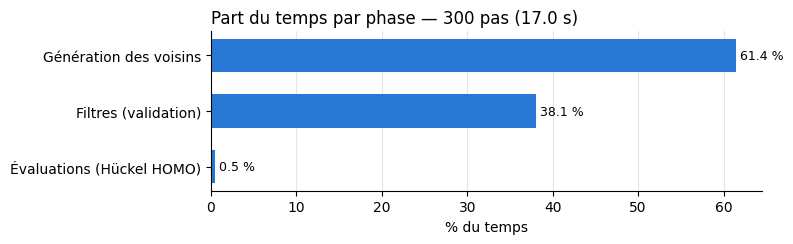

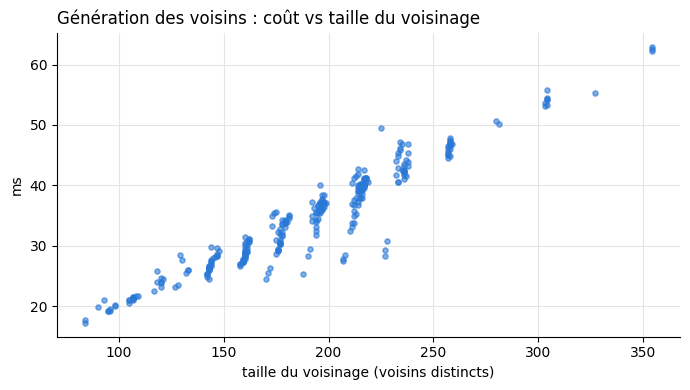

In [3]:
phases = {
    "Génération des voisins": steps.t_neighbors.sum(),
    "Filtres (validation)": steps.t_filters.sum(),
    "Évaluations (Hückel HOMO)": steps.t_evaluations.sum(),
}
total = sum(phases.values())
hbar(list(phases), [100 * v / total for v in phases.values()],
     f"Part du temps par phase — {N_STEPS} pas ({total:.1f} s)", "% du temps", fmt="{:.1f} %")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(steps.neighborhood_size, 1000 * steps.t_neighbors, s=14, color=BLUE, alpha=0.6)
ax.set_xlabel("taille du voisinage (voisins distincts)"); ax.set_ylabel("ms")
ax.set_title("Génération des voisins : coût vs taille du voisinage", loc="left")
plt.tight_layout(); plt.show()

## 2 — Validation paresseuse vs complète

`count_valid_neighbors=True` valide **tout** le voisinage à chaque pas (comme l'original, qui en tirait
la taille du voisinage valide). Par défaut on s'arrête au premier voisin valide dans l'ordre aléatoire.
Les deux marches divergent après le premier pas (le générateur aléatoire n'est pas consommé pareil) :
on compare des moyennes par pas. Les autres options viennent de la cellule de paramètres.

In [4]:
def timed_walk(n, **kw):
    t0 = time.perf_counter()
    df = pd.DataFrame(random_walk(START, n, filters, **{**WALK_OPTIONS, **kw})).iloc[1:]
    return df, time.perf_counter() - t0

lazy, t_lazy = timed_walk(N_STEPS_EAGER, count_valid_neighbors=False)
eager, t_eager = timed_walk(N_STEPS_EAGER, count_valid_neighbors=True)

cmp = pd.DataFrame({
    "paresseuse (défaut)": [1000 * t_lazy / N_STEPS_EAGER, lazy.n_filter_calls.mean(),
                            1000 * lazy.t_neighbors.mean(), 1000 * lazy.t_filters.mean()],
    "complète (original)": [1000 * t_eager / N_STEPS_EAGER, eager.n_filter_calls.mean(),
                            1000 * eager.t_neighbors.mean(), 1000 * eager.t_filters.mean()],
}, index=["ms / pas", "appels aux filtres / pas", "ms voisins / pas", "ms filtres / pas"]).round(1)
print(f"Accélération : x{t_eager / t_lazy:.1f}")
print(f"Voisins valides (validation complète) : {eager.n_valid_neighbors.mean():.0f} / "
      f"{eager.neighborhood_size.mean():.0f} en moyenne "
      f"({100 * (eager.n_valid_neighbors / eager.neighborhood_size).mean():.0f} %)")
cmp

Accélération : x7.5
Voisins valides (validation complète) : 30 / 164 en moyenne (17 %)


,paresseuse (défaut),complète (original)
ms / pas,48.8,365.8
appels aux filtres / pas,9.6,164.5
ms voisins / pas,35.1,29.2
ms filtres / pas,13.6,336.4


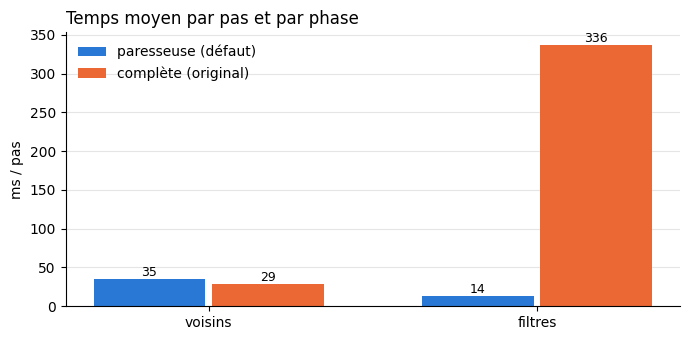

In [5]:
labels = ["voisins", "filtres"]
x = range(len(labels))
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, (name, df, color) in enumerate([("paresseuse (défaut)", lazy, BLUE), ("complète (original)", eager, ORANGE)]):
    vals = [1000 * df.t_neighbors.mean(), 1000 * df.t_filters.mean()]
    pos = [i + (k - 0.5) * 0.36 for i in x]
    ax.bar(pos, vals, width=0.34, color=color, label=name)
    for p, v in zip(pos, vals):
        ax.text(p, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels(labels); ax.set_ylabel("ms / pas")
ax.set_title("Temps moyen par pas et par phase", loc="left"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 3 — Coût de chaque filtre

On enveloppe le `_evaluate` de chaque filtre d'un chronomètre, puis on fait une marche en validation complète
(tous les voisins passent dans la chaîne de filtres). `is_valid_molecule` s'arrête au premier rejet :
un filtre placé tard ne voit que les molécules acceptées par ceux d'avant.

NB : `UnknownGCF` / `UnknownECFP` calculent les fragments ; `FilterUnknownGCF` / `FilterUnknownECFP` ne font
que lire la valeur et rejeter.

In [6]:
filter_stats = defaultdict(lambda: {"appels": 0, "temps (s)": 0.0, "rejets": 0})

def instrument(ev):
    original = type(ev)._evaluate
    def timed(mol, _ev=ev):
        s = filter_stats[_ev.name]
        t = time.perf_counter()
        try:
            return original(_ev, mol)
        except EvaluationError:
            s["rejets"] += 1
            raise
        finally:
            s["appels"] += 1
            s["temps (s)"] += time.perf_counter() - t
    ev._evaluate = timed
    return ev

instrumented = [instrument(f) for f in build_filters()]
random_walk(START, 30, instrumented, **{**WALK_OPTIONS, "count_valid_neighbors": True})

fs = pd.DataFrame(filter_stats).T
fs["µs / appel"] = 1e6 * fs["temps (s)"] / fs["appels"]
fs["% rejet"] = 100 * fs["rejets"] / fs["appels"]
fs = fs.round(2)
fs

,appels,temps (s),rejets,µs / appel,% rejet
huckel_compatible,5768.0,0.62,1426.0,107.30,24.72
UnknownGCF_chembl_zinc,4342.0,3.97,0.0,913.31,0.00
FilterUnknownGCF,4342.0,0.00,1304.0,0.73,30.03
UnknownECFP_chembl_zinc,3038.0,0.57,0.0,188.22,0.00
FilterUnknownECFP,3038.0,0.00,1935.0,1.11,63.69
heteroatom_chain_filter,1103.0,5.24,0.0,4748.17,0.00


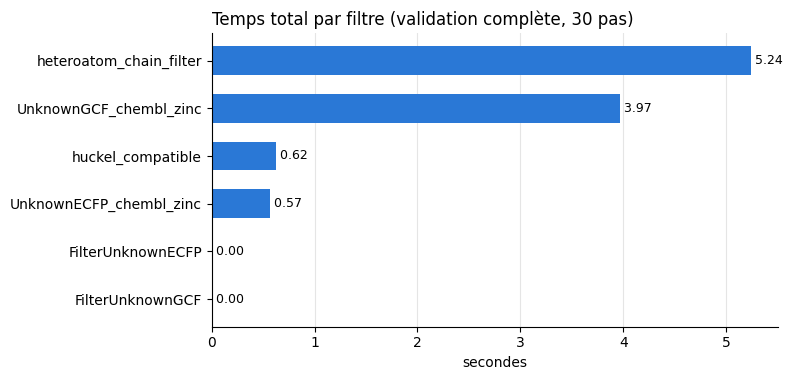

In [7]:
hbar(list(fs.index), list(fs["temps (s)"]), "Temps total par filtre (validation complète, 30 pas)", "secondes")

## 4 — Coût par type de mutation

Sur un échantillon de molécules de la marche : temps pour **lister** les actions (`list_actions`) et pour
**produire** chaque voisin (`apply_smiles` = copie du graphe + mutation + `update_representation` + SMILES canonique).

In [8]:
sample = list(walk.smiles.iloc[::10])
per_action = defaultdict(lambda: {"voisins": 0, "list_actions (s)": 0.0, "apply_smiles (s)": 0.0})

for smi in sample:
    mol = Molecule(smi)
    for action_cls in MolecularGraph.action_space:
        s = per_action[action_cls.__name__]
        t = time.perf_counter()
        actions = action_cls.list_actions(mol)
        s["list_actions (s)"] += time.perf_counter() - t
        t = time.perf_counter()
        for action in actions:
            action.apply_smiles()
        s["apply_smiles (s)"] += time.perf_counter() - t
        s["voisins"] += len(actions)

pa = pd.DataFrame(per_action).T
pa["total (s)"] = pa["list_actions (s)"] + pa["apply_smiles (s)"]
pa["µs / voisin"] = 1e6 * pa["apply_smiles (s)"] / pa["voisins"].clip(lower=1)
pa = pa.sort_values("total (s)", ascending=False).round(4)
print(f"{len(sample)} molécules échantillonnées")
pa

31 molécules échantillonnées


,voisins,list_actions (s),apply_smiles (s),total (s),µs / voisin
MoveGroupMG,5045.0,0.0158,0.8863,0.9021,175.6723
ChangeBondMG,3281.0,0.0209,0.5835,0.6044,177.8378
SubstituteAtomMG,2257.0,0.0038,0.3843,0.3881,170.2836
AddAtomMG,1946.0,0.0017,0.3351,0.3368,172.2021
InsertCarbonMG,616.0,0.0029,0.1117,0.1146,181.3678
CutAtomMG,293.0,0.0050,0.0521,0.0570,177.7840
RemoveAtomMG,217.0,0.0095,0.0384,0.0479,177.1023


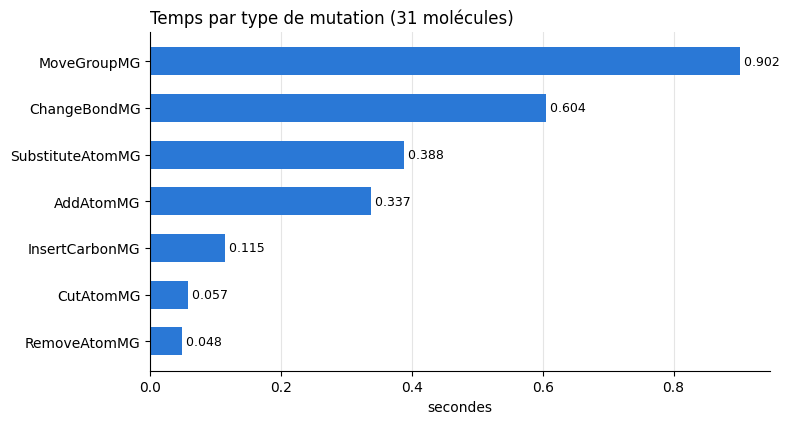

In [9]:
hbar(list(pa.index), list(pa["total (s)"]), f"Temps par type de mutation ({len(sample)} molécules)", "secondes", fmt="{:.3f}")

## 5 — cProfile : quelles fonctions prennent le temps

Le profilage tourne dans un sous-processus (`scripts/Lea/profile_random_walk.py`) : les hooks du kernel
(debugpy) empêchent `cProfile.enable()` ici. Même marche et mêmes options que la section 1, sans les évaluations Hückel.
Regroupement des postes identique à `profile_run.py`. Le temps C de `MolFromSmiles`/`MolToSmiles`
est imputé à l'appelant Python (poste `MolecularGraph …`).

300 pas en 22.4 s (avec surcoût cProfile) — 57,282 voisins produits, 4,371 validations


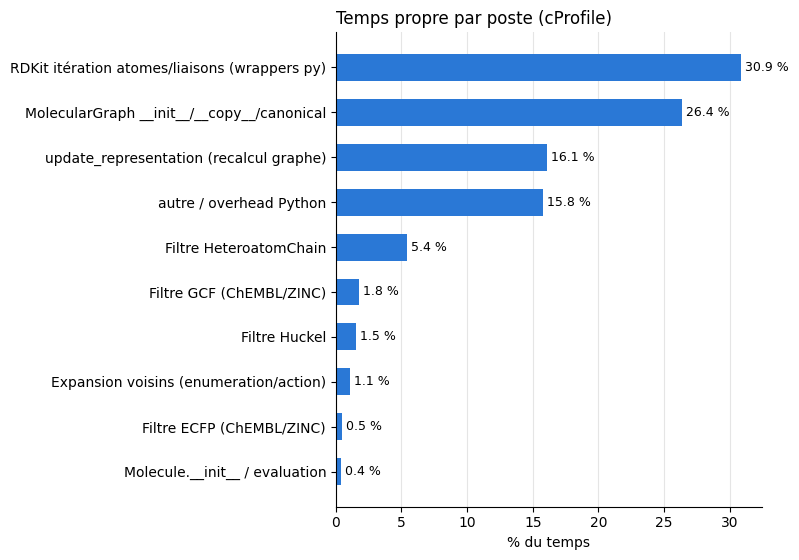

,poste,tottime,appels,%
5,RDKit itération atomes/liaisons (wrappers py),6.91,21921360,30.9
10,MolecularGraph __init__/__copy__/canonical,5.90,880718,26.4
4,update_representation (recalcul graphe),3.60,75480,16.1
13,autre / overhead Python,3.53,0,15.8
7,Filtre HeteroatomChain,1.21,948,5.4
9,Filtre GCF (ChEMBL/ZINC),0.40,25168,1.8
6,Filtre Huckel,0.34,259528,1.5
11,Expansion voisins (enumeration/action),0.26,346253,1.1
8,Filtre ECFP (ChEMBL/ZINC),0.12,3706,0.5
12,Molecule.__init__ / evaluation,0.09,184619,0.4


In [10]:
proc = subprocess.run(
    [sys.executable, os.path.join(ROOT, "scripts", "Lea", "profile_random_walk.py"),
     "--steps", str(N_STEPS), "--max-atoms", str(MAX_ATOMS), "--start", START, "--json", *PROFILE_FLAGS],
    capture_output=True, text=True, cwd=ROOT, check=True,
)
prof = json.loads(proc.stdout.strip().splitlines()[-1])
print(f"{prof['steps']} pas en {prof['wall']:.1f} s (avec surcoût cProfile) — "
      f"{prof['n_neighbors']:,} voisins produits, {prof['n_filter_calls']:,} validations")

roll = pd.DataFrame(prof["rollup"]).query("tottime > 0").sort_values("tottime", ascending=False)
roll["%"] = (100 * roll.tottime / roll.tottime.sum()).round(1)
hbar(list(roll.poste), list(roll["%"]), "Temps propre par poste (cProfile)", "% du temps", fmt="{:.1f} %")
roll.round(2)

In [11]:
stats = pstats.Stats(prof["prof"])
raw = stats.stats  # {(fichier, ligne, fonction): (cc, nc, tottime, cumtime, callers)}

def short(fn, ln, name):
    fn = os.path.relpath(fn, ROOT) if fn.startswith(ROOT) else os.path.basename(fn)
    return f"{name}  ({fn}:{ln})"

KEY = ["neighbor_actions", "compute_possible_actions", "list_actions", "apply_smiles", "raw_copy",
       "update_representation", "is_valid_molecule", "__init__", "get_representation", "evaluate"]
key_rows = [
    {"fonction": short(fn, ln, name), "appels": nc, "cumtime (s)": ct, "tottime (s)": tt}
    for (fn, ln, name), (cc, nc, tt, ct, _) in raw.items()
    if name in KEY and (fn.startswith(os.path.join(ROOT, "evomol")))
]
print("Appels clés d'evomol (temps cumulé, sous-appels inclus) :")
pd.DataFrame(key_rows).sort_values("cumtime (s)", ascending=False).head(15).round(3)

Appels clés d'evomol (temps cumulé, sous-appels inclus) :


,fonction,appels,cumtime (s),tottime (s)
0,neighbor_actions (evomol/search/random_walk.p...,300,14.070,0.511
9,apply_smiles (evomol/action/molecular_graph/a...,57875,12.562,0.056
1,update_representation (evomol/representation/...,75480,10.319,3.604
4,is_valid_molecule (evomol/evaluation/evaluati...,4672,6.948,0.006
2,evaluate (evomol/evaluation/evaluation.py:64),16147,6.942,0.020
5,__init__ (evomol/representation/molecular_gra...,9497,1.858,0.797
7,__init__ (evomol/representation/molecule.py:93),4373,1.237,0.006
10,compute_possible_actions (evomol/representati...,300,0.986,0.003
6,raw_copy (evomol/representation/molecular_gra...,60859,0.606,0.591
25,list_actions (evomol/action/molecular_graph/c...,300,0.330,0.058


In [12]:
top = pd.DataFrame(
    [{"fonction": short(fn, ln, name), "appels": nc, "tottime (s)": tt, "cumtime (s)": ct}
     for (fn, ln, name), (cc, nc, tt, ct, _) in raw.items()]
).sort_values("tottime (s)", ascending=False).head(20).round(3)
print("Top 20 par temps propre :")
top

Top 20 par temps propre :


,fonction,appels,tottime (s),cumtime (s)
52,canonical_smiles (evomol/representation/molec...,67837,3.781,3.781
71,update_representation (evomol/representation/...,75480,3.604,10.319
89,_getRDKitItem (__init__.py:90),4176091,2.467,2.467
88,_sizeCalc (__init__.py:87),4506951,2.048,2.048
224,_evaluate (evomol/evaluation/huckel_filters.p...,301,1.208,1.242
95,__getitem__ (__init__.py:65),4183410,0.879,6.391
108,__init__ (evomol/representation/molecular_gra...,9497,0.797,1.858
31,<built-in method builtins.len> (~:0),4661513,0.613,3.187
79,__len__ (__init__.py:60),4349087,0.604,2.573
134,raw_copy (evomol/representation/molecular_gra...,60859,0.591,0.606


## 6 — Ce que coûtait l'original

Dans `RevoMol-correlation/scripts/walk.py`, `get_random_neighbor` appelle `dp.setup_filters("chembl_zinc")`
**dans la compréhension de liste, pour chaque voisin** : à chaque appel, `UnknownGCF` et `UnknownECFP`
relisent `gcf2.txt` et `ecfp4_ChEMBL_ZINC.txt` depuis le disque. Estimation de ce seul surcoût :

In [13]:
n = 3
t = time.perf_counter()
for _ in range(n):
    dp.setup_filters("chembl_zinc")
t_setup = (time.perf_counter() - t) / n

n_neigh = steps.neighborhood_size.mean()
print(f"1 appel à setup_filters('chembl_zinc') : {1000 * t_setup:.0f} ms")
print(f"x {n_neigh:.0f} voisins/pas  ->  ~{t_setup * n_neigh:.1f} s/pas rien qu'en rechargement des bases")
print(f"Marche adaptée (section 1)              : {wall / N_STEPS:.3f} s/pas tout compris")

1 appel à setup_filters('chembl_zinc') : 323 ms
x 191 voisins/pas  ->  ~61.6 s/pas rien qu'en rechargement des bases
Marche adaptée (section 1)              : 0.057 s/pas tout compris


## Conclusion (run du notebook : 300 pas, max 30 atomes, seed 0)

Les chiffres absolus dépendent de la machine. Les proportions, elles, sont stables.

**1. Presque tout le temps part dans la génération du voisinage, pas dans les filtres.**
94 ms/pas, dont environ 88 % à produire les ~446 voisins du pas, alors qu'on n'en valide qu'environ 7.
Dans `apply_smiles` (29 s cumulées sur 36 s profilées), le temps se répartit entre :
- `canonical_smiles` (écriture SMILES RDKit) : 7.8 s ;
- `update_representation` : 6.9 s de temps propre ;
- l'itération Python sur les atomes et liaisons RDKit : 36 % du total, 43 M d'appels aux wrappers.

**2. Les filtres pèsent moins de 3 % grâce à la validation paresseuse.**
Le coût par appel est surtout élevé pour HeteroatomChain (~1 400 µs) et UnknownGCF (~620 µs).
Viennent ensuite ECFP (~140 µs) et Hückel (~90 µs). ECFP rejette 79 % de ce qui lui parvient.
Valider tout le voisinage, comme le fait l'original, rend la marche ~6 fois plus lente (×5.9).

**3. Tous les types de mutation coûtent pareil par voisin (~165 µs).** Le coût total suit donc le nombre
de voisins produits. MoveGroupMG en produit le plus (~40 %) et pèse le plus.

**4. L'original rechargeait les bases ChEMBL/ZINC pour chaque voisin**, soit environ 350 ms × 446,
c'est-à-dire ~2.5 min par pas. Ce seul point domine tout le reste.

**Leviers, du plus rentable au moins rentable :**
- Ne pas produire tout le voisinage : tirer les actions au hasard et n'appliquer que celles-ci
  jusqu'au premier voisin valide (~7 au lieu de ~446). Compromis : la loi devient uniforme sur les **actions**,
  et non plus sur les voisins **distincts** (un voisin atteint par k actions devient k fois plus probable).
- Alléger le coût par voisin dans `apply_smiles` : calculer la clé SMILES sans le
  `update_representation` complet, et réduire les itérations Python sur atomes et liaisons.
